# Compare approximations

In [1]:
%matplotlib inline
import importlib
from DataAnalysis.functions import plot_spectra
import matplotlib.pyplot as plt
from collections import Counter
from DataAnalysis.functions.plot_spectra import *

## Choose datasets to compare
First, provide the filepath and filename of your simulated spectra datasets. The metadata-files have to be on the same directory and with unchanged name.
Second, create dataframes from your files by using the get_df_and_data() function.
Finally, add your dataframes and data to "dataframes" and "data" list.
Note that all dataframes will be compared to the one called "df_without_approx".


In [2]:
path = "../results/simulated_spectra/"

a0L1 = "20250601_181609_generatedSpectra.csv"   #a0L1: IK-0, Level 1
a0L2 = "20250604_122016_generatedSpectra.csv"
a0L3 = "20250603_190357_generatedSpectra.csv"
a1L1 = "20250603_164142_generatedSpectra.csv"
a1L2 = "20250603_161100_generatedSpectra.csv"
a1L3 = "20250603_102118_generatedSpectra.csv"
a2L1 = "20250602_224027_generatedSpectra.csv"
a2L2 = "20250603_134651_generatedSpectra.csv"
a2L3 = "20250603_153450_generatedSpectra.csv"
without_approx = "YYYY0625_HHmmss_combined_HPC.csv"

# Compute pandas dataframes from data (change names if needed and delete unwanted)
dfa0L1, da0L1 = get_df_and_data(path,a0L1)
dfa0L2, da0L2 = get_df_and_data(path,a0L2)
dfa0L3, da0L3 = get_df_and_data(path,a0L3)
dfa1L1, da1L1 = get_df_and_data(path,a1L1)
dfa1L2, da1L2 = get_df_and_data(path,a1L2)
dfa1L3, da1L3 = get_df_and_data(path,a1L3)
dfa2L1, da2L1 = get_df_and_data(path,a2L1)
dfa2L2, da2L2 = get_df_and_data(path,a2L2)
dfa2L3, da2L3 = get_df_and_data(path,a2L3)
# The one they will be compared to:
df_without_approx, data_without_approx = get_df_and_data(path,without_approx)

# Add dataframes and data to the list:
dataframes = [dfa0L1, dfa0L2,dfa0L3,dfa1L1,dfa1L2,dfa1L3, dfa2L1,dfa2L2,dfa2L3,df_without_approx]
datas = [da0L1, da0L2, da0L3, da1L1, da1L2, da1L3, da2L1, da2L2, da2L3, data_without_approx]
df_without_approx.dropna(subset=['spectrum'], inplace=True)


## Computation-time comparison

In [3]:
for df in dataframes:
    df.dropna(subset=['spectrum'],inplace=True)
for i in range(len(dataframes)):
    print(f'{datas[i]["approx"]} lv. {datas[i]["approx_level"]}: {dataframes[i]["computation_time"].sum()}')

IK-0 lv. 1: 1824.2729365
IK-0 lv. 2: 1126.9794274
IK-0 lv. 3: 1361.3659933000001
IK-1 lv. 1: 1023.1138586
IK-1 lv. 2: 1061.1743621
IK-1 lv. 3: 948.43748
IK-2 lv. 1: 1776.8133326000002
IK-2 lv. 2: 1861.8748438999999
IK-2 lv. 3: 1807.7639822
none lv. 1: 71993.70382200001


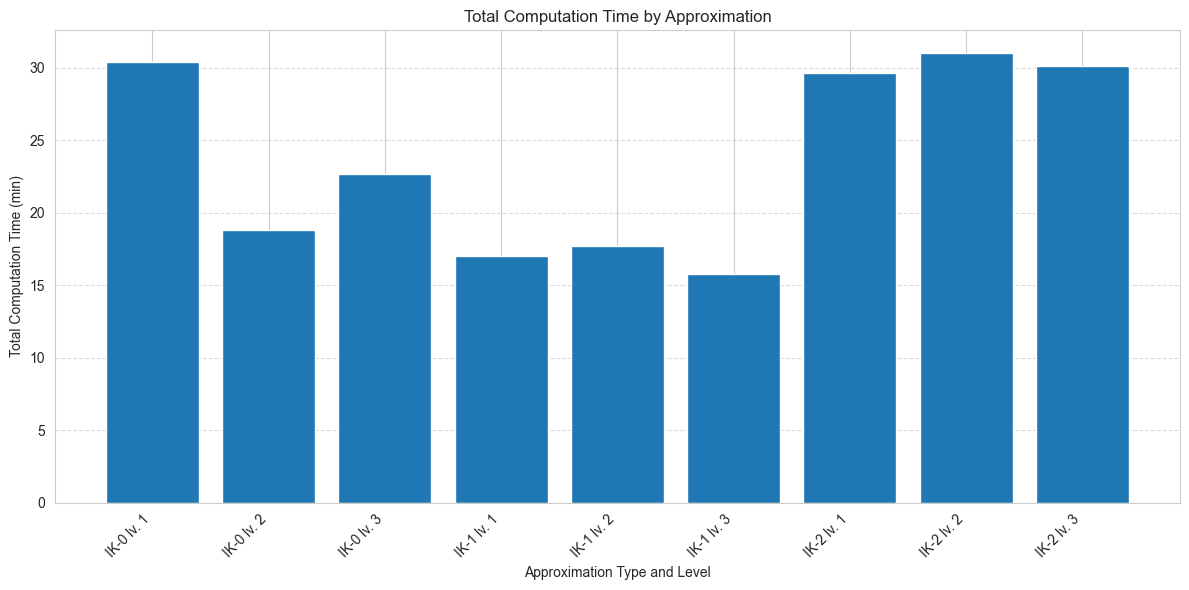

In [6]:
%matplotlib inline
computation_times = []
labels = []

for i in range(len(dataframes)-1):
    total_time = dataframes[i]['computation_time'].sum()
    computation_times.append(total_time/60)

    if datas[i]["approx_level"]: # Check if approx_level exists
        labels.append(f'{datas[i]["approx"]} lv. {datas[i]["approx_level"]}')
    else:
        labels.append(f'{datas[i]["approx"]}') # For 'No Approx' case

plt.figure(figsize=(12, 6)) # Adjust figure size as needed
plt.bar(labels, computation_times)
plt.xlabel('Approximation Type and Level')
plt.ylabel('Total Computation Time (min)')
plt.title('Total Computation Time by Approximation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Compare all to without approx

#### sum of distances

In [7]:
from DataAnalysis.functions.plot_spectra import compare_all_comparable_spectra
import importlib

means = []
for i in range(len(dataframes)):
    spectra1 = compare_all_comparable_spectra(df_without_approx)
    spectra2 = compare_all_comparable_spectra(dataframes[i])
    data2 = datas[i]
    shared_names = set(spectra1.keys()) & set(spectra2.keys())

    npoints = data2["npoints"]
    if data_without_approx["npoints"] != npoints:
        print("Attention: not same amount of data")
        print(data2["npoints"])

    mean_per_molecule = []
    n_compareable = 0
    for name in shared_names:
        intensities1 = spectra1[name]
        intensities2 = spectra2[name]
        if len(intensities2)<=10:
            continue
        n_compareable+=1
        diff_sum = sum(abs(intensities1[i] - intensities2[i]) for i in range(npoints))
        mean_per_molecule.append(diff_sum / npoints)

    # Output statistics
    print(f"Approximation: {data2['approx']}, lv: {data2['approx_level']}")
    print(f'comparable molecules: {n_compareable}')
    print(f"Minimum: {np.min(mean_per_molecule)}")
    print(f"Maximum: {np.max(mean_per_molecule)}")
    print(f"Mittelwert: {np.mean(mean_per_molecule)}")
    print(f"Median: {np.median(mean_per_molecule)}")
    print(f"Standardabweichung: {np.std(mean_per_molecule)}")
    print(20*"=")
    means.append(np.mean(mean_per_molecule))


Approximation: IK-0, lv: 1
comparable molecules: 972
Minimum: 1.3809931485227687e-19
Maximum: 0.018941737000591072
Mittelwert: 0.0031412621174383803
Median: 0.002605348854717976
Standardabweichung: 0.002671177430784498
Approximation: IK-0, lv: 2
comparable molecules: 959
Minimum: 2.874969010973215e-18
Maximum: 0.014858825342955686
Mittelwert: 0.002317957857301319
Median: 0.0010872225383999439
Standardabweichung: 0.0027955404928971693
Approximation: IK-0, lv: 3
comparable molecules: 918
Minimum: 4.7703301269877285e-18
Maximum: 0.01167258469904451
Mittelwert: 0.0008261184722718378
Median: 0.0001126498294846377
Standardabweichung: 0.001511041542658886
Approximation: IK-1, lv: 1
comparable molecules: 959
Minimum: 2.062210130307843e-18
Maximum: 0.018941737000591072
Mittelwert: 0.0031838443984881183
Median: 0.0026508149781064266
Standardabweichung: 0.002663895007729501
Approximation: IK-1, lv: 2
comparable molecules: 959
Minimum: 2.062210130307843e-18
Maximum: 0.018907752724765622
Mittelwert

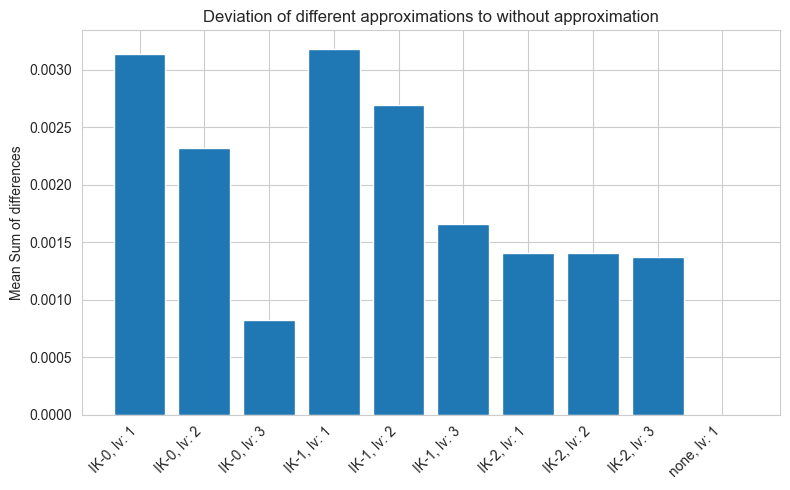

In [8]:
%matplotlib inline
labels = [f'{data["approx"]}, lv: {data["approx_level"]}' for data in datas]

plt.figure(figsize=(8, 5))
plt.bar(range(len(means)), means, tick_label=labels)
plt.ylabel("Mean Sum of differences")
plt.title("Deviation of different approximations to without approximation")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### cosine similarity

In [9]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_means = []
for i in range(len(dataframes)):
    spectra1 = compare_all_comparable_spectra(df_without_approx)
    spectra2 = compare_all_comparable_spectra(dataframes[i])
    data2 = datas[i]
    shared_names = set(spectra1.keys()) & set(spectra2.keys())

    npoints = data2["npoints"]
    if data_without_approx["npoints"] != npoints:
        print("Attention: not same amount of data")
        print(data2["npoints"])

    mean_per_molecule = []
    for name in shared_names:
        X = np.array(spectra1.get(name)).reshape(1,-1)
        Y = np.array(spectra2.get(name)).reshape(1,-1)
        s = cosine_similarity(X,Y)
        mean_per_molecule.append(s)
    cosine_means.append(np.mean(mean_per_molecule))
    print(f'{data2["approx"]}, lv. {data2["approx_level"]}: {np.mean(mean_per_molecule):.4f}')

IK-0, lv. 1: 0.6348
IK-0, lv. 2: 0.8070
IK-0, lv. 3: 0.9661
IK-1, lv. 1: 0.6298
IK-1, lv. 2: 0.7374
IK-1, lv. 3: 0.8593
IK-2, lv. 1: 0.8710
IK-2, lv. 2: 0.8710
IK-2, lv. 3: 0.8767
none, lv. 1: 1.0000


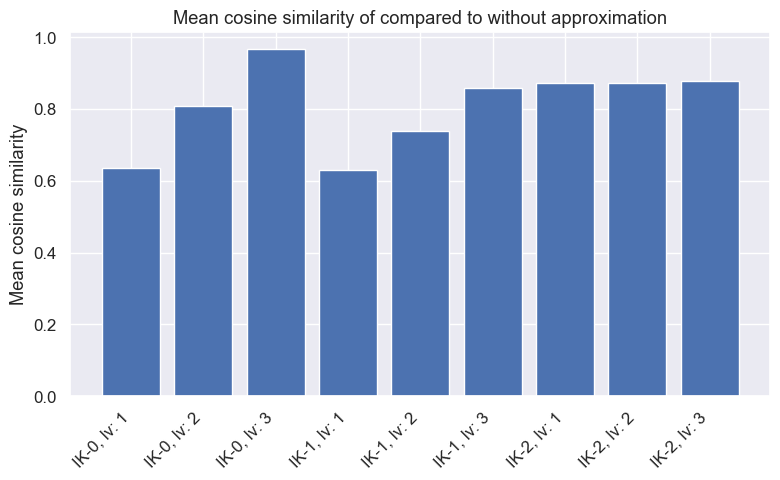

In [14]:
%matplotlib inline
import seaborn as sns
labels = [f'{data["approx"]}, lv: {data["approx_level"]}' for data in datas[:-1]]

plt.figure(figsize=(8, 5))
sns.set_theme(font_scale=1.1)
plt.bar(range(len(cosine_means)-1), cosine_means[:-1], tick_label=labels)
plt.ylabel("Mean cosine similarity")
plt.title("Mean cosine similarity of compared to without approximation")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### similarity per n_spins

Here is a little checkup if we have to expect worse prediction with a growing number of spins. To check that you will see the plots from every approximation where the cosine similarities are grouped and the mean value of these cosine similarities is plotted.

In [15]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_per_nSpins_dicts = []
for i in range(len(dataframes)):
    n_spins_dict = {}
    spectra1 = compare_all_comparable_spectra(df_without_approx)
    spectra2 = compare_all_comparable_spectra(dataframes[i])
    data2 = datas[i]
    shared_names = set(spectra1.keys()) & set(spectra2.keys())

    npoints = data2["npoints"]
    if data_without_approx["npoints"] != npoints:
        print("Attention: not same amount of data")
        print(data2["npoints"])

    for name in shared_names:
        row = dataframes[i].loc[dataframes[i]["Name"] == name]
        n_spins = row["n_spins"].iloc[0]
        X = np.array(spectra1.get(name)).reshape(1,-1)
        Y = np.array(spectra2.get(name)).reshape(1,-1)
        s = cosine_similarity(X,Y)
        if n_spins not in n_spins_dict:
            n_spins_dict[n_spins] = []
        n_spins_dict[n_spins].append(s)
    similarity_per_nSpins_dicts.append(n_spins_dict)

for approx_dict in similarity_per_nSpins_dicts:
    print(20*"=")
    print("New Approximation")
    sorted_n_spins = sorted(approx_dict.keys())
    mean_similarities = [np.mean(approx_dict[key]) for key in sorted_n_spins]
    for x in range(1,len(mean_similarities)):
        print(f'{x}: {float(mean_similarities[x]):.4f}')

New Approximation
1: 0.7432
2: 0.4807
3: 0.5159
4: 0.6130
5: 0.6567
6: 0.6988
7: 0.6434
8: 0.6799
9: 0.7084
10: 0.7006
11: 0.6469
12: 0.7158
New Approximation
1: 0.7899
2: 0.7985
3: 0.7804
4: 0.8304
5: 0.8243
6: 0.7591
7: 0.8157
8: 0.6631
9: 0.8402
10: 0.6680
11: 0.7444
New Approximation
1: 0.9624
2: 0.9466
3: 0.9720
4: 0.9648
5: 0.9631
6: 0.9681
7: 0.9164
8: 0.9731
9: 0.9419
10: 0.8664
New Approximation
1: 0.4807
2: 0.5159
3: 0.6130
4: 0.6567
5: 0.6988
6: 0.6434
7: 0.6799
8: 0.7084
9: 0.7006
10: 0.6469
11: 0.7158
New Approximation
1: 0.7899
2: 0.8009
3: 0.6583
4: 0.7709
5: 0.7665
6: 0.6766
7: 0.7292
8: 0.6327
9: 0.7239
10: 0.6491
11: 0.7405
New Approximation
1: 0.9617
2: 0.9088
3: 0.8458
4: 0.8458
5: 0.7897
6: 0.7442
7: 0.8547
8: 0.7824
9: 0.8110
10: 0.8614
New Approximation
1: 1.0000
2: 0.9993
3: 0.9833
4: 0.8458
5: 0.8458
6: 0.7997
7: 0.7442
8: 0.9596
9: 0.7824
10: 0.8247
11: 0.9951
New Approximation
1: 1.0000
2: 0.9993
3: 0.9833
4: 0.8458
5: 0.8458
6: 0.7997
7: 0.7442
8: 0.9596
9: 

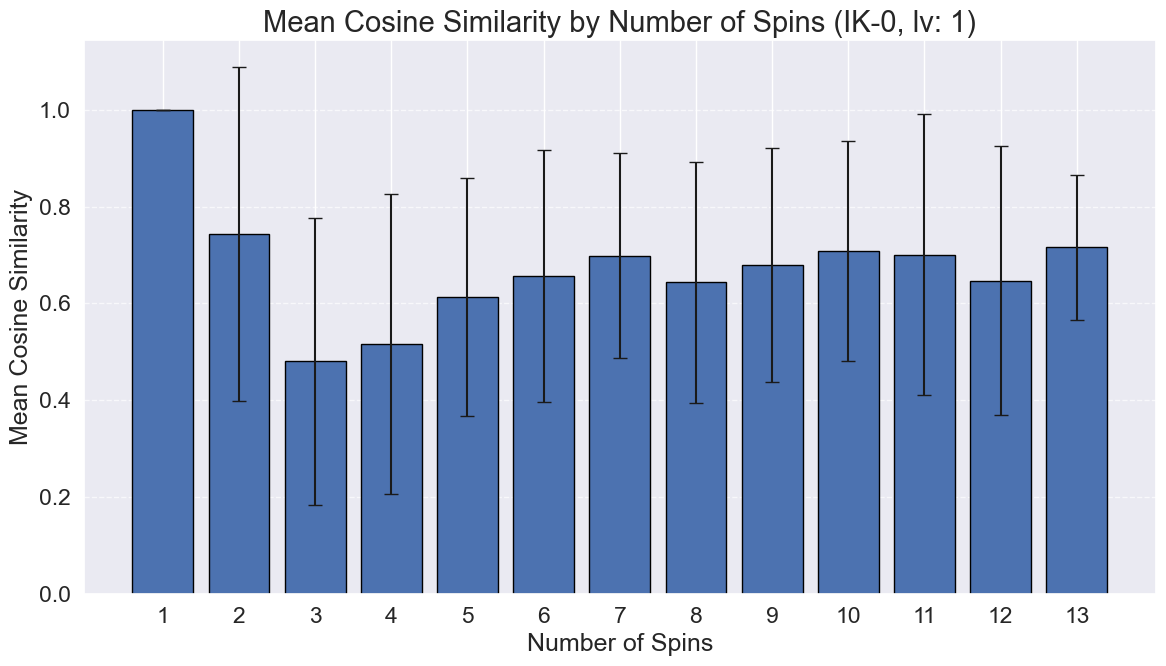

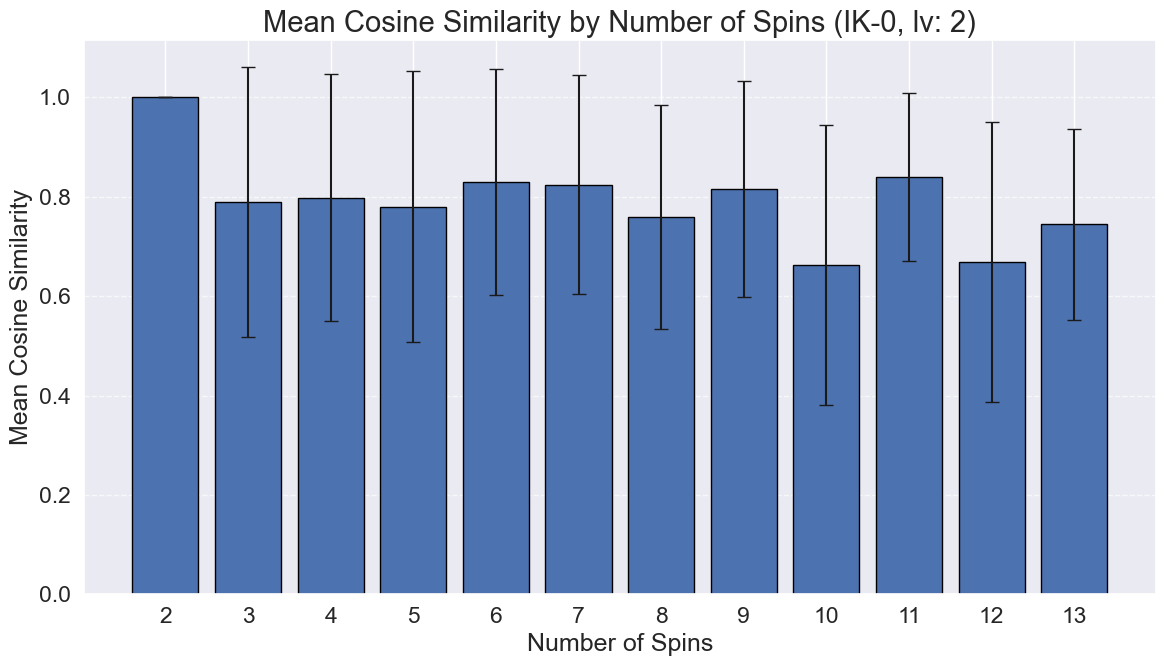

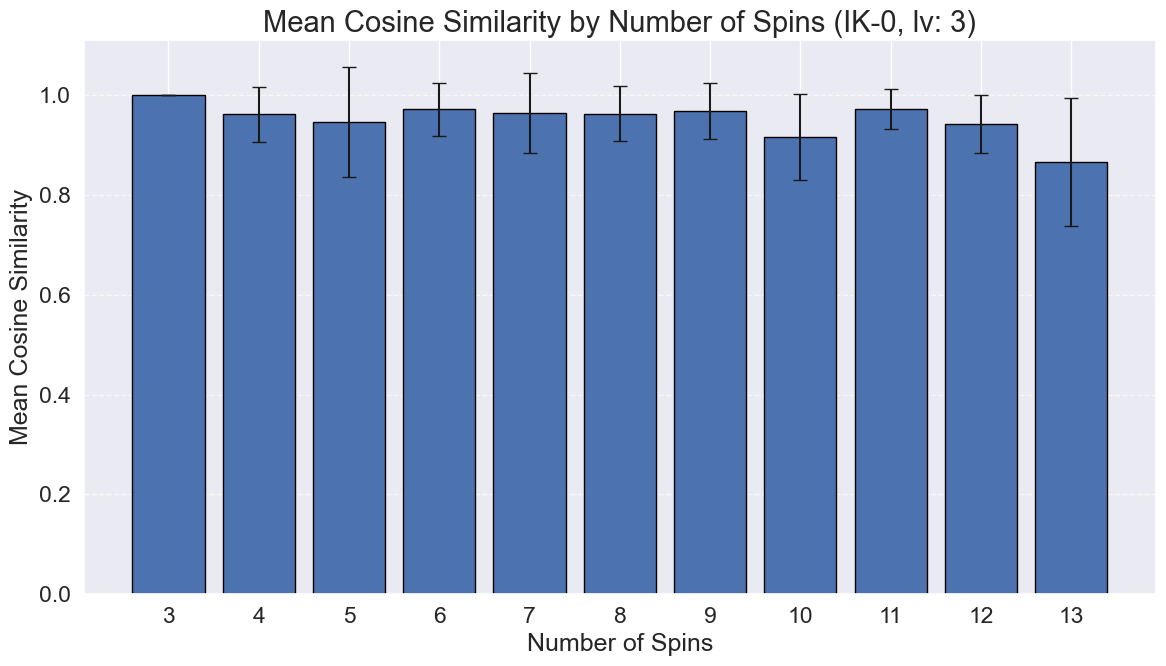

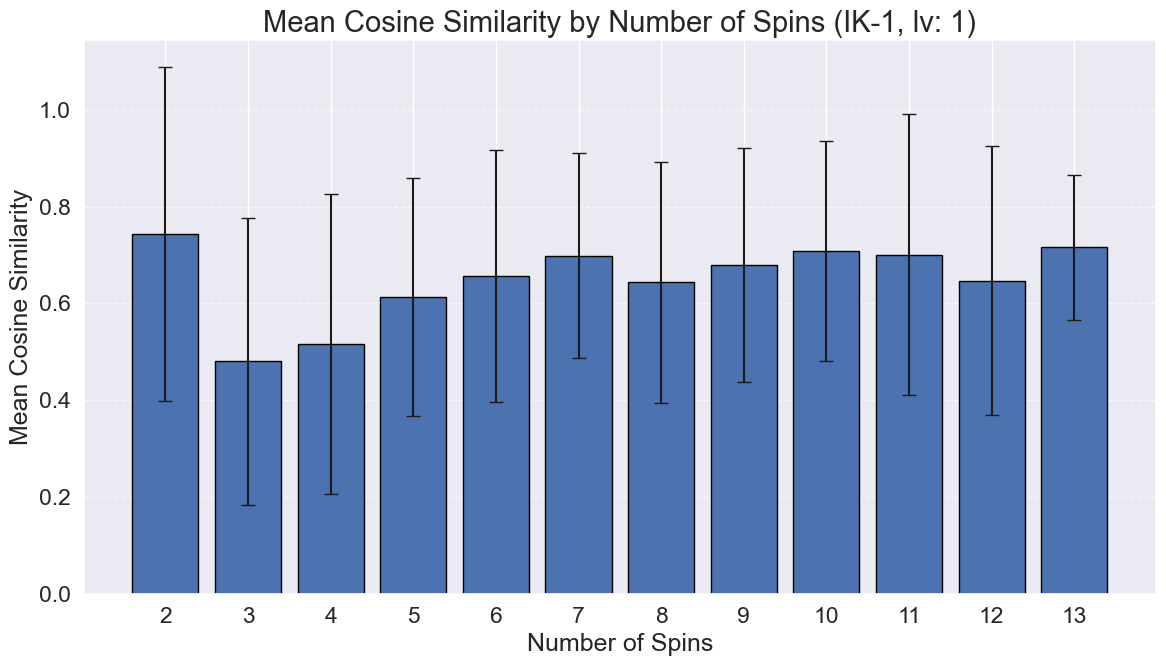

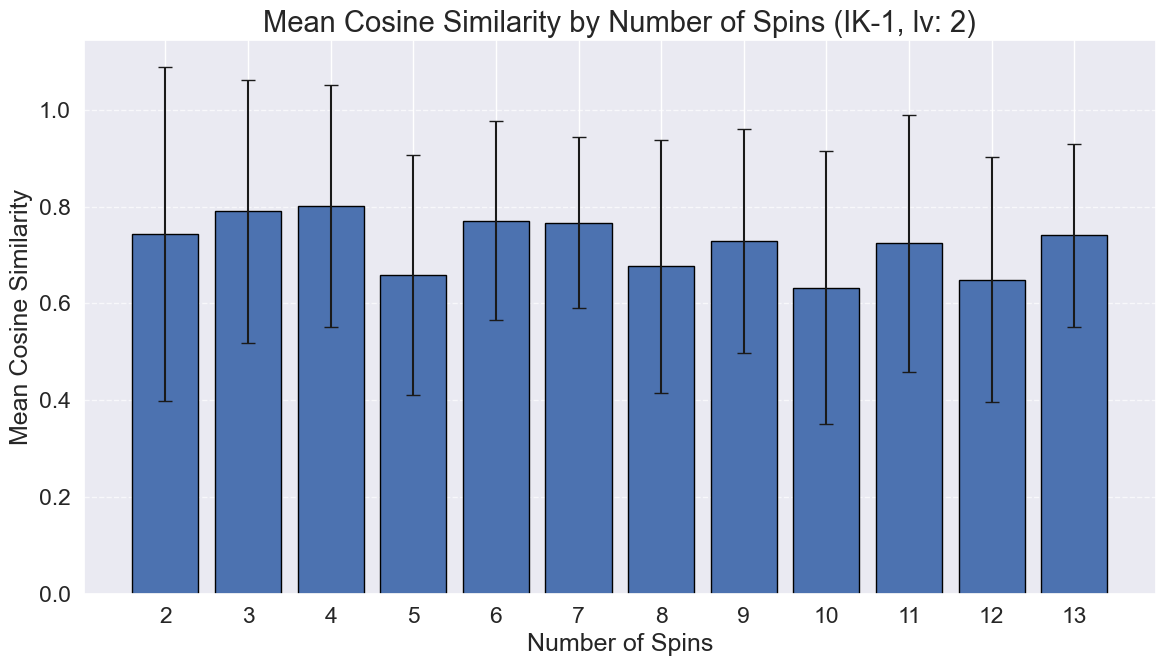

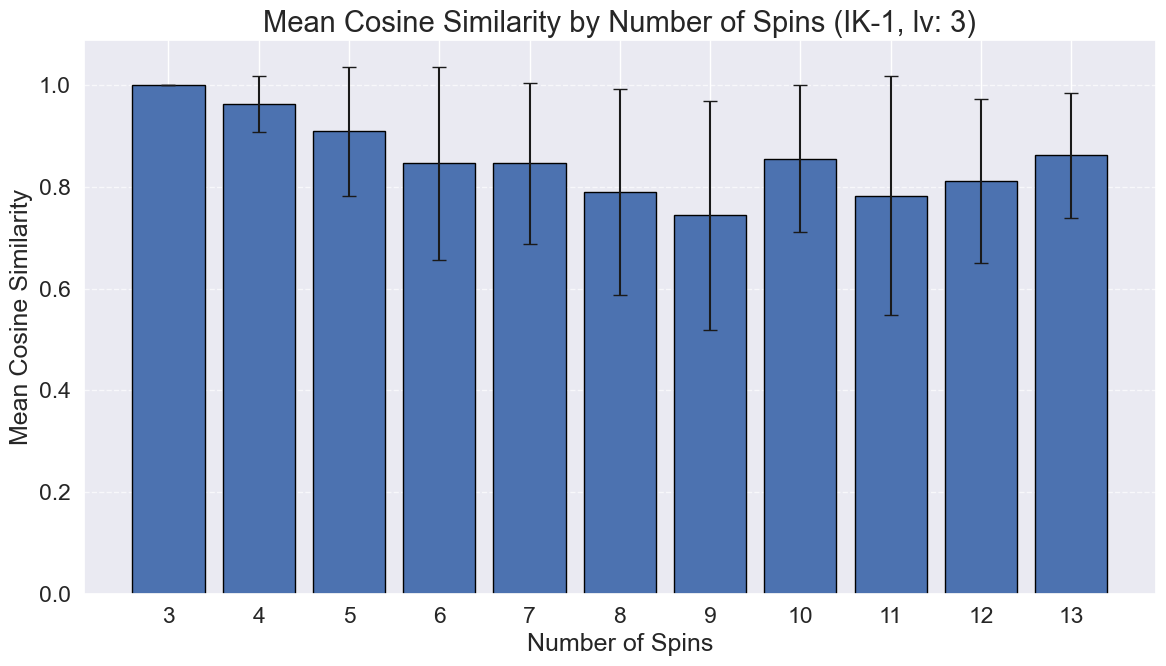

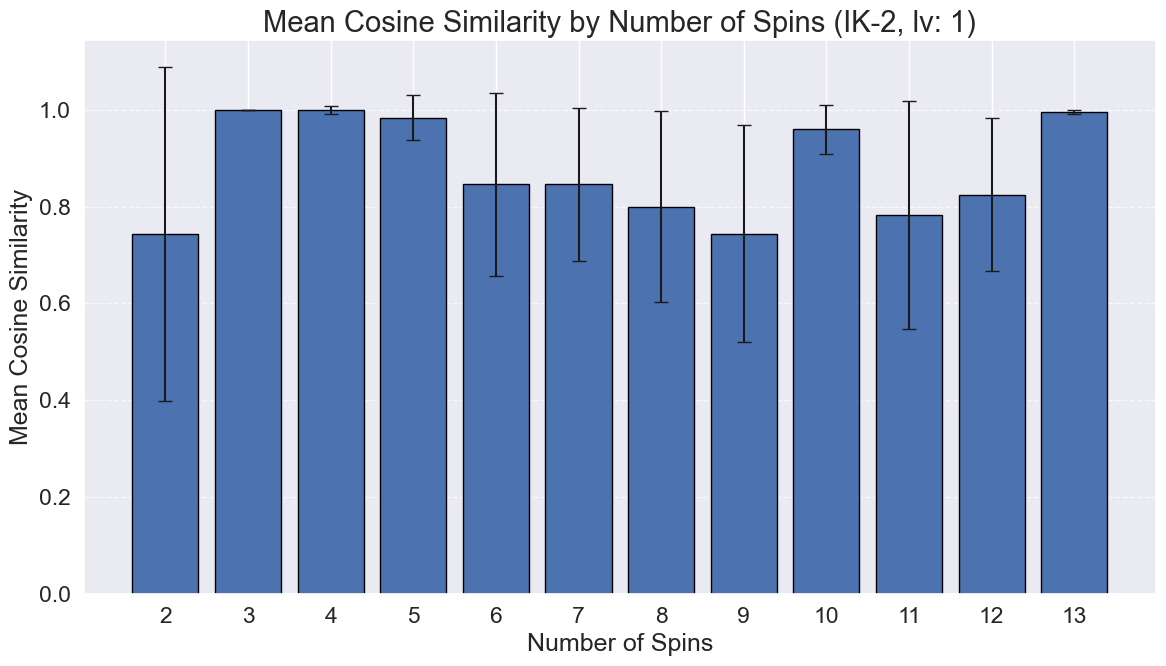

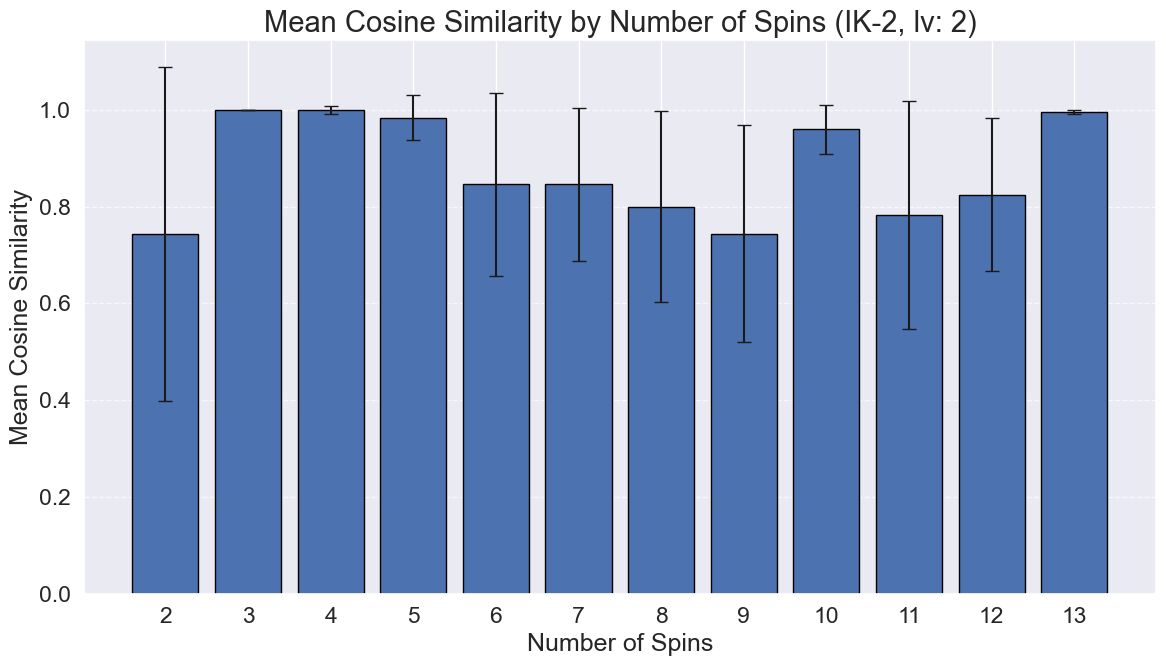

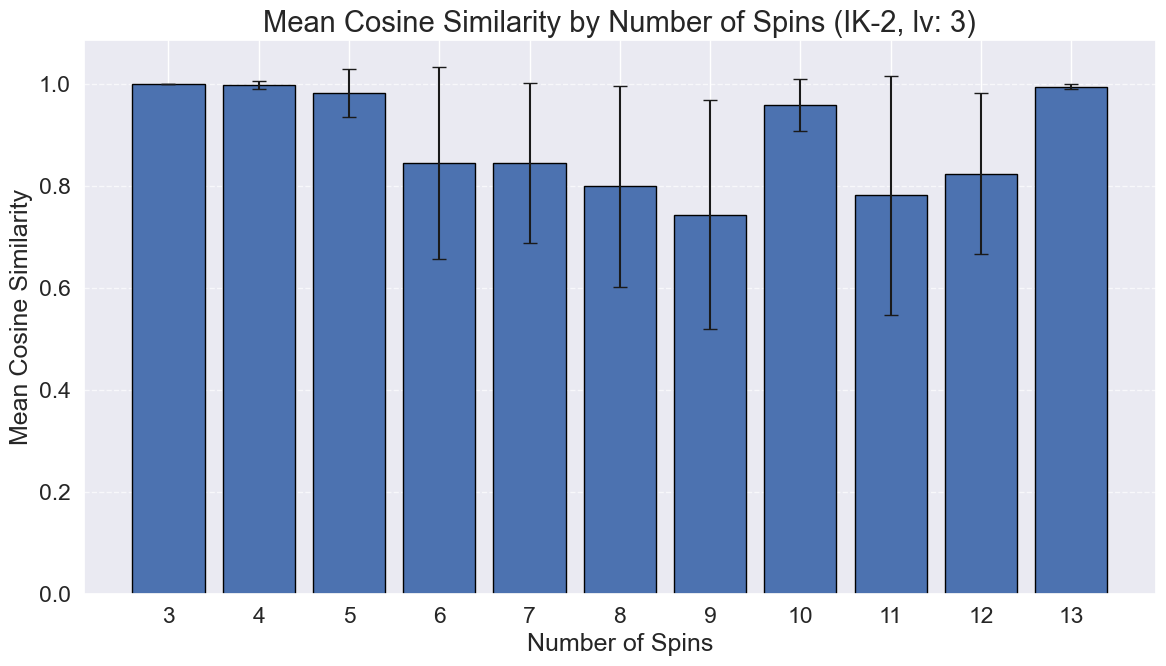

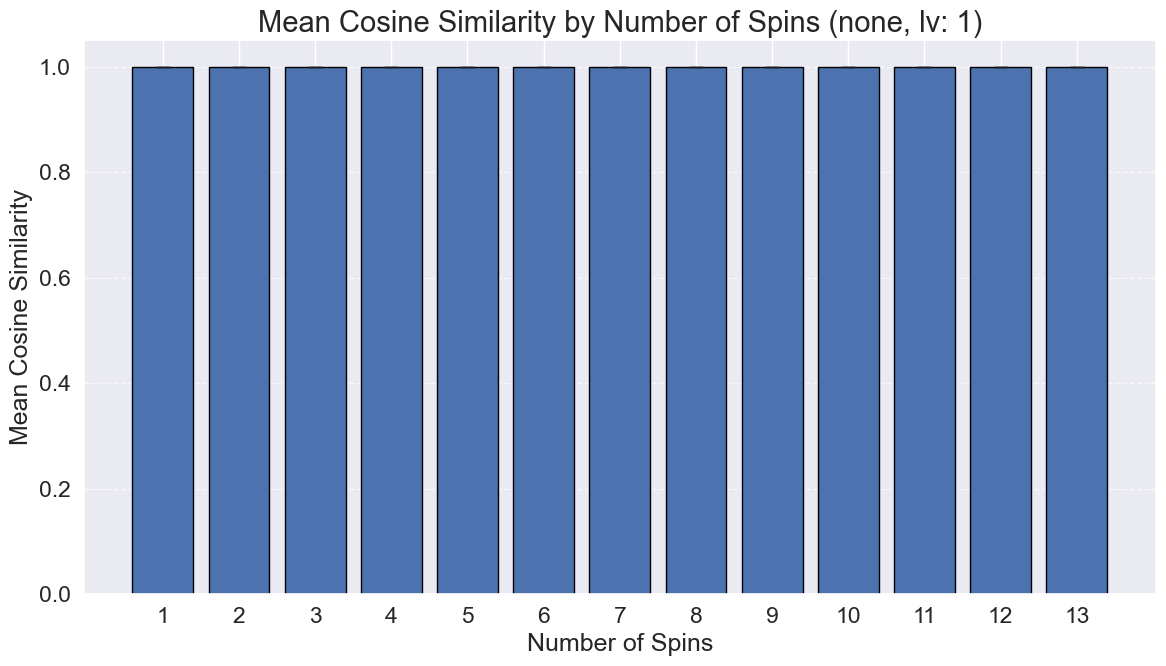

In [40]:
%matplotlib inline
import seaborn as sns
idx=0
for n_spins_dict in similarity_per_nSpins_dicts:
    sorted_n_spins = sorted(n_spins_dict.keys())
    mean_similarities = [np.mean(n_spins_dict[key]) for key in sorted_n_spins]
    std_similarities = [np.std(n_spins_dict[key]) for key in sorted_n_spins]

    approx, approx_lvl = datas[idx]["approx"], datas[idx]["approx_level"]
    plt.figure(figsize=(12, 7))
    plt.bar(
        x=sorted_n_spins,
        height=mean_similarities,
        yerr=std_similarities,
        capsize=5,
        edgecolor='black'
    )
    sns.set_theme(font_scale=1.5)

    # Add labels and title
    plt.xlabel("Number of Spins", fontsize=18)
    plt.ylabel("Mean Cosine Similarity", fontsize=18)
    plt.title(f"Mean Cosine Similarity by Number of Spins ({approx}, lv: {approx_lvl})", fontsize=21)
    plt.xticks(sorted_n_spins) # Ensure all sorted n_spins are shown as ticks
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    idx +=1

#### Peak comparison

In [23]:
from DataAnalysis.functions.approx_analysis import *
for idx, row in df_without_approx.iloc[:100].iterrows():
    spectrum_without_approx, molecule = get_spectral_data(df_without_approx, idx+1)
    spectrum_with_approx, molecule2 = get_spectral_data(dfa2L1, idx+1, molecule=molecule)
    if molecule == molecule2:
        print("=========="+molecule+"==========")
        print(f'Index: {idx -3}')
        print(f'without approx: {count_peaks(spectrum_without_approx)}')
        print(f'with approx: {count_peaks(spectrum_with_approx)}\n')


==========AMP==========
Index: -3
without approx: 21
with approx: 21

==========ATP==========
Index: -2
without approx: 22
with approx: 22

==========Adenine==========
Index: -1
without approx: 2
with approx: 2

==========Adenosine==========
Index: 0
without approx: 20
with approx: 20

==========Agmatine==========
Index: 1
without approx: 21
with approx: 8

==========Alpha-ketoglutaric-acid==========
Index: 2
without approx: 10
with approx: 10

==========4-Aminobenzoic-acid==========
Index: 3
without approx: 4
with approx: 4

==========Anthranilic-acid==========
Index: 4
without approx: 10
with approx: 10

==========5-Acetylamido-2-chloroaniline==========
Index: 5
without approx: 9
with approx: 9

==========ADA==========
Index: 6
without approx: 2
with approx: 2

==========5-Acetylamino-2-nitrobenzoic-acid==========
Index: 7
without approx: 9
with approx: 9

==========2-Amino-5-ethyl-1,3,4-thiadiazole==========
Index: 8
without approx: 7
with approx: 7

==========Alpha-naphthoic-acid==

Row index: 0, Counter g: 1, Molecule: 5-Aminovaleric acid
AMP
Row index: 1, Counter g: 2, Molecule: AMP
ATP
Row index: 2, Counter g: 3, Molecule: ATP
Adenine
Row index: 3, Counter g: 4, Molecule: Adenine
Adenosine
Row index: 4, Counter g: 5, Molecule: Adenosine
Agmatine
Row index: 5, Counter g: 6, Molecule: Agmatine
Alpha-ketoglutaric-acid
Row index: 6, Counter g: 7, Molecule: Alpha-ketoglutaric-acid
4-Aminobenzoic-acid
Row index: 7, Counter g: 8, Molecule: 4-Aminobenzoic-acid
Anthranilic-acid
Row index: 8, Counter g: 9, Molecule: Anthranilic-acid
5-Acetylamido-2-chloroaniline
Row index: 9, Counter g: 10, Molecule: 5-Acetylamido-2-chloroaniline
ADA
Row index: 10, Counter g: 11, Molecule: ADA
5-Acetylamino-2-nitrobenzoic-acid
Row index: 11, Counter g: 12, Molecule: 5-Acetylamino-2-nitrobenzoic-acid
2-Amino-5-ethyl-1,3,4-thiadiazole
Row index: 12, Counter g: 13, Molecule: 2-Amino-5-ethyl-1,3,4-thiadiazole
Alpha-naphthoic-acid
Row index: 13, Counter g: 14, Molecule: Alpha-naphthoic-acid
A

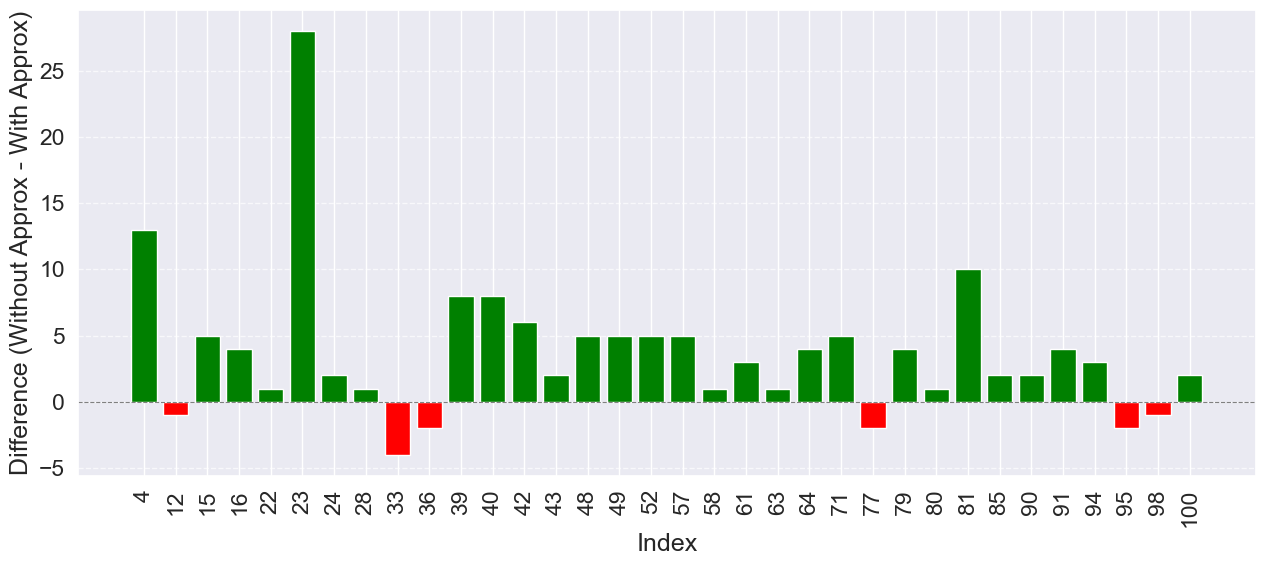

In [43]:
# Choose Subset
%matplotlib inline
subset_from = 0
sucset_to = 100

all_without_approx_values = []
all_with_approx_values = []
all_indices = []
for idx, row in df_without_approx.iloc[subset_from:sucset_to].iterrows():
    spectrum_without_approx, molecule = get_spectral_data(df_without_approx, idx+1)
    spectrum_with_approx, molecule2 = get_spectral_data(dfa2L1, idx+1, molecule=molecule)
    if molecule == molecule2:
        # Capture values and index
        val_without_approx = count_peaks(spectrum_without_approx)
        val_with_approx = count_peaks(spectrum_with_approx)
        all_without_approx_values.append(val_without_approx)
        all_with_approx_values.append(val_with_approx)
        all_indices.append(idx)
        print(molecule)

# --- Filter and Plot only the differences where values differ ---
differing_values_delta = []
differing_indices_for_plot = []

for i in range(len(all_indices)):
    if all_without_approx_values[i] != all_with_approx_values[i]:
        delta = all_without_approx_values[i] - all_with_approx_values[i]
        differing_values_delta.append(delta)
        differing_indices_for_plot.append(all_indices[i]) # Store the original index


plt.figure(figsize=(max(10, int(len(differing_indices_for_plot) * 0.4)), 6))
colors = ['red' if d < 0 else 'green' for d in differing_values_delta]
plt.bar(range(len(differing_values_delta)), differing_values_delta, color=colors)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8) # Add a horizontal line at zero
plt.xlabel('Index')
sns.set_theme(font_scale=1.5)
plt.ylabel('Difference (Without Approx - With Approx)')
plt.xticks(range(len(differing_indices_for_plot)), differing_indices_for_plot, rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

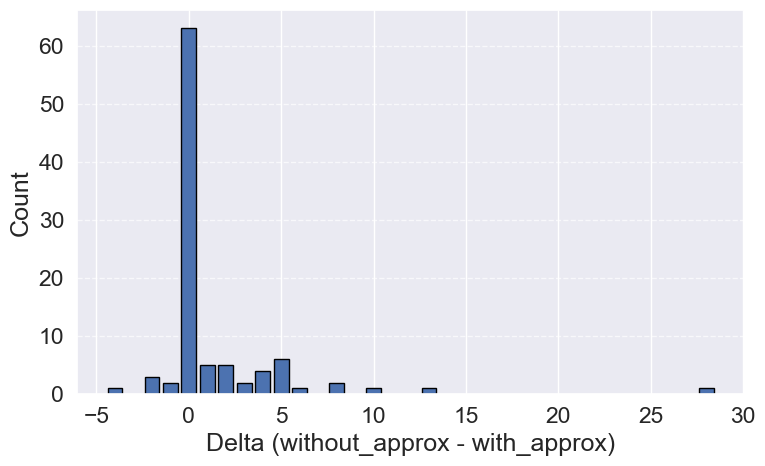

In [30]:


deltas = [a - b for a, b in zip(all_without_approx_values, all_with_approx_values)]
delta_counts = Counter(deltas)

sorted_deltas = sorted(delta_counts.items())
x_vals = [item[0] for item in sorted_deltas]
y_vals = [item[1] for item in sorted_deltas]

plt.figure(figsize=(8, 5))
plt.bar(x_vals, y_vals, edgecolor='black')
plt.xlabel('Delta (without_approx - with_approx)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## Plot spectra

You can run this part if you want to take a look at some specific spectra, especially if you saw noticable peak counts in the part before. You can specify the spectra you want to plot by changing the range of indices and the approximation you want to take a look at in the first lines.

In [10]:
index_from = 20
index_to = 23
approximation = dfa2L1  # dfa2L1 = approximation: IK-2, Level 1

%matplotlib tk
importlib.reload(plot_spectra)
from DataAnalysis.functions.plot_spectra import *
import matplotlib.pyplot as plt

def parse_array_string(array_str):
    try:
        array_str = array_str.strip('"[]')
        array_str = array_str.replace(';', '')
        array_str = array_str.replace('  ', ' ')
        array_str = ','.join(array_str.split())
        return np.fromstring(array_str, sep=',')
    except Exception as e:
        print("Error parsing array string:", e)
        return np.array([])


for idx, row in df_without_approx.iloc[index_from:index_to].iterrows():
    spectrum_without_approx, molecule = get_spectral_data(df_without_approx, idx+1)
    spectrum_with_approx, molecule2 = get_spectral_data(approximation, idx+1, molecule=molecule)

    ppm = parse_array_string(row['ppm'])

    if spectrum_without_approx.size > 0 and spectrum_with_approx.size > 0 and ppm.size > 0:
        plt.figure(figsize=(10, 4))
        plt.plot(ppm, spectrum_without_approx, label='Without Approx', color='#e94634')
        plt.plot(ppm, spectrum_with_approx, label=F'{da0L3["approx"]} lv. {da0L3["approx_level"]}', color='#448087') #Todo: fix
        plt.xlabel('Chemical Shift (ppm)')
        plt.ylabel('Intensity')
        plt.title(f"Spectrum: {molecule}")

        plt.gca().invert_xaxis()
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print(f"Skipping row {idx} due to missing or malformed data.")

## Plot gissmo spectra


In [38]:
import seaborn as sns
%matplotlib tk
df_temp = pd.read_csv("../data/sampled_gissmo.csv")

for x in range(8,11):
    plt.figure(figsize=(10, 4))
    plt.title(f'{x:} {df_temp["Name"][x-1]}')
    df = pd.read_csv(f'../data/gissmo/{x}.csv')
    sns.lineplot(df, x=df.ppm,y=df.val)

In [33]:
df_temp = pd.read_csv("../data/sampled_gissmo.csv")